# 09 · 变系数三维扩散：有限体积参考解 + FNO

**前置：** 07、线性代数中的共轭梯度。**目标：** 从解析标签走向数值标签，同时输入系数场与 forcing，区分神经网络误差和离散误差。

在周期单位立方体解 $-\nabla\cdot(a(\boldsymbol x)\nabla u)+u=f$，$a>0$。这是带反应项的 Darcy 型椭圆问题。算子现在是 $(a,f)\mapsto u$，不能在 Fourier 空间逐模式直接除法，因为变系数耦合频率。

反应项保证周期问题唯一可解；没有它时还需 forcing 均值相容条件和解的均值约束。本章不使用 Dirichlet 边界，也不声称复现标准 Darcy 数据集。

数据在本机生成，无外部文件。求解器用守恒中心通量与预条件共轭梯度（PCG），代码完整放在下面。

## 原理详解 A：变系数方程为何不能用一个谱分母求解？

本章的算子是
$$
\mathcal A_a u=-\nabla\cdot(a\nabla u)+u.
$$
展开散度得到 $-a\Delta u-\nabla a\cdot\nabla u+u$。当 a 随空间改变时，空间乘法在 Fourier 域变成频率卷积，各模式被耦合。只有常系数时才能把它写成独立模式上的简单除法。

连续问题对应弱形式：对任意周期测试函数 w，
$$
\int_\Omega a\nabla u\cdot\nabla w+uw\,d\boldsymbol x
=\int_\Omega fw\,d\boldsymbol x.
$$
令 $w=u$ 可看到能量
$$
\int_\Omega a|\nabla u|^2+|u|^2\,d\boldsymbol x.
$$
如果 $a\ge a_{\min}>0$，该能量控制解的梯度与幅度。反应项还消除了周期纯扩散问题的常数自由度。这是使用对称正定离散算子和共轭梯度的理论依据。

网络输入是两条函数 a 与 f，而不只是一个参数。不同系数场改变了局部传输能力，也改变了整个区域的响应。因此解一般不是逐点用 f 除以 a，而是一个全局耦合结果。

## 原理详解 B：共享面通量与调和平均的来源

沿一个方向，相邻点的间距为 h。假设一个面两侧各占半个间距，分别具有系数 $a_i,a_{i+1}$，相同通量穿过两个串联区段，总“阻力”相加：
$$
F_{i+1/2}=
\frac{u_{i+1}-u_i}{h/(2a_i)+h/(2a_{i+1})}
=a_{i+1/2}\frac{u_{i+1}-u_i}{h},
$$
$$
a_{i+1/2}=\frac{2a_ia_{i+1}}{a_i+a_{i+1}}.
$$
这解释了调和平均与串联导通关系。对光滑系数它也是合理的面系数近似；对强跳变系数，面处理需要更仔细分析。

负散度在节点上计算为
$$
-\frac{F_{i+1/2}-F_{i-1/2}}h
=\frac{a_{i+1/2}(u_i-u_{i+1})+
a_{i-1/2}(u_i-u_{i-1})}{h^2}.
$$
代码沿三个方向分别累加，并加上 u。roll(-1) 取前邻点，roll(1) 取后邻点；周期滚动同时实现跨边界的邻接。相邻点用同一面系数与相反通量，保证内部通量抵消。

离散矩阵虽然没有显式构造，但其作用可以写成
$$
A_hu=u+\sum_d\frac{
a_{d,+}(u-u_{d,+})+a_{d,-}(u-u_{d,-})}{h_d^2}.
$$
对任意非零向量 z，
$$
z^TA_hz=\sum_i z_i^2+
\sum_{d,\text{前向面}}\frac{a_{\rm face}}{h_d^2}(z_{i+1}-z_i)^2>0.
$$
同一正系数出现在两个相邻位置的对称矩阵项中，故矩阵对称正定。SPD 检查验证的是离散实现是否符合这个结构。

## 原理详解 C：PCG 的每个变量在做什么？

PCG 求 $A_hu=f$。它不用保存稠密 $N^3\times N^3$ 矩阵，只需反复调用矩阵—向量作用。对角 Jacobi 预条件矩阵为
$$
M_{ii}=1+\sum_d\frac{a_{d,+}+a_{d,-}}{h_d^2}.
$$
迭代从 $u_0=0$ 开始，残差 $r_0=f-A_hu_0$，预条件残差 $z_0=M^{-1}r_0$，搜索方向 $p_0=z_0$。随后：
$$
\rho_n=r_n^Tz_n,\quad
\alpha_n=\frac{\rho_n}{p_n^TA_hp_n},
$$
$$
u_{n+1}=u_n+\alpha_np_n,\qquad
r_{n+1}=r_n-\alpha_nA_hp_n,
$$
$$
z_{n+1}=M^{-1}r_{n+1},\quad
\beta_n=\frac{r_{n+1}^Tz_{n+1}}{\rho_n},\quad
p_{n+1}=z_{n+1}+\beta_np_n.
$$
p 不是普通的负梯度方向；共轭关系帮助不同迭代纠正互不重复的误差分量。预条件意在改善谱分布与有效条件数，不改变要求解的方程。系数对比度更高或网格更细时，Jacobi 的改善可能不够，需要更强预条件器。

代码 flatten(1) 后只对空间维求和，得到每个样本独立的内积和步长；不能把整个 batch 也求和，否则不同 PDE 实例会错误共用迭代系数。已收敛样本通过 active mask 停止更新，其余样本继续迭代。

停止标准是相对代数残差 $\|A_hu-f\|_2/\|f\|_2$。最终重新计算真实残差，而不是只信任递推的 r，可检查浮点累计误差。标签转成 float32 后重新诊断的残差可能稍大于 PCG 双精度停止阈值，这不表示原求解没有收敛。

## 原理详解 D：制造解、网格误差与代理误差

离散制造解先任选 $u_*$，再定义 $f_h=A_hu_*$。如果 PCG 恢复了 $u_*$，说明线性求解器可靠；但一个错误的离散算子也可能通过它自己的制造解检查。因此还必须用已知的连续 PDE 解验证离散精度。

常系数单模式在连续与离散方程中的本征值不同：
$$
\lambda_{\rm cont}=1+4\pi^2|\boldsymbol k|^2,\qquad
\lambda_h=1+\sum_d\frac4{h_d^2}\sin^2(\pi k_dh_d).
$$
利用 $\sin z=z+O(z^3)$，可得光滑低频情况下二阶网格误差。本章从 8³ 到 16³、32³ 的实验就在检查这个差别，而不是再检查 PCG 步数。

设连续解为 u，离散参考解为 $u_h$，网络为 $u_{\theta,h}$，则
$$
\|u_{\theta,h}-P_hu\|
\le\|u_{\theta,h}-u_h\|+\|u_h-P_hu\|.
$$
第一项是代理模型对标签的误差，第二项是参考解离散误差。把 PCG tol 从 1e-9 降到 1e-12 主要改善代数求解误差，通常不会显著改善固定网格的第二项。

变系数没有本章这种简单连续解析解，所以细网格解抽样到粗网格后的差异用于估计网格变化。若已处于稳定的二阶渐近区，可进一步做 Richardson 外推；没有确认该条件时，不能把粗细差直接叫作精确连续误差。

本章 FNO 的高分辨率输出也与细网格重新求解的标签比较，明确区分模型迁移误差与参考离散本身的变化。

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "tutorial_utils.py").exists():
    ROOT = ROOT / "neural_operator_tutorials"
if not (ROOT / "tutorial_utils.py").exists():
    raise FileNotFoundError("Start Jupyter in PINO or neural_operator_tutorials")
sys.path.insert(0, str(ROOT))
import torch
get_ipython().run_line_magic("matplotlib", "inline")
from tutorial_utils import *
from tutorial_3d_utils import *
seed_all()
print("device:", DEVICE, "| smoke:", SMOKE)


device: cpu | smoke: False


## 1. 守恒面通量与 SPD 算子

格点间的面系数取调和平均 $a_{i+1/2}=2a_i a_{i+1}/(a_i+a_{i+1})$。面通量为 $a_{i+1/2}(u_{i+1}-u_i)/h$，相邻格点共享同一面通量。对每个方向求通量差，并加 $u$。

离散能量是反应能量与各边的正梯度能量之和，因此当 $a>0$ 时算子对称正定。PCG 使用对角 Jacobi 预条件。所有参考求解内部计算使用 float64。

In [2]:
def diffusion_faces(a):
    return [2*a*torch.roll(a,-1,dims=d)/(a+torch.roll(a,-1,dims=d))
            for d in (-3,-2,-1)]

def apply_diffusion(u,a,faces=None):
    if faces is None: faces = diffusion_faces(a)
    result = u.clone()
    for d,face in zip((-3,-2,-1),faces):
        h = 1/u.shape[d]
        backward = torch.roll(face,1,dims=d)
        result = result+(face*(u-torch.roll(u,-1,dims=d))
                        +backward*(u-torch.roll(u,1,dims=d)))/h**2
    return result

def pcg_solve(a,f,tol=1e-9,maxiter=400):
    a,f = a.double(),f.double()
    if not (a>0).all(): raise ValueError("Diffusion coefficient must be positive")
    faces = diffusion_faces(a)
    diagonal = torch.ones_like(a)
    for d,face in zip((-3,-2,-1),faces):
        diagonal += (face+torch.roll(face,1,dims=d))*a.shape[d]**2
    def dot(p,q): return (p*q).flatten(1).sum(1)
    def expand(v): return v[:,None,None,None]
    u = torch.zeros_like(f)
    r = f.clone(); z = r/diagonal; p = z.clone()
    rz = dot(r,z)
    fnorm = f.flatten(1).norm(dim=1).clamp_min(1e-30)
    for iteration in range(maxiter):
        relative = r.flatten(1).norm(dim=1)/fnorm
        active = relative>tol
        if not active.any(): break
        Ap = apply_diffusion(p,a,faces)
        alpha = torch.where(active,rz/dot(p,Ap).clamp_min(1e-30),0.)
        u = u+expand(alpha)*p
        r = r-expand(alpha)*Ap
        z = r/diagonal
        next_rz = dot(r,z)
        beta = torch.where(active,next_rz/rz.clamp_min(1e-30),0.)
        p = z+expand(beta)*p
        rz = next_rz
    actual = apply_diffusion(u,a,faces)-f
    final = actual.flatten(1).norm(dim=1)/fnorm
    if final.max()>5*tol:
        raise RuntimeError(f"PCG did not converge: relative residual {final.max().item():.2e}")
    return u,{"iterations":iteration+1,"max_relative_residual":final.max().item()}

## 2. 先验证求解器，再生成机器学习数据

制造离散解：先选 $u_*$，计算 $f_h=A_hu_*$，PCG 应还原 $u_*$。这检查线性求解正确性；它**不**检查连续 PDE 的离散精度。第二个检查用已知的连续解和网格加密，观察离散误差减小。

In [3]:
check_grid = periodic_grid3d(8,dtype=torch.float64)
acheck = (1+0.2*torch.sin(2*torch.pi*check_grid[0]))[None]
ucheck = torch.sin(2*torch.pi*(check_grid.sum(0)))[None]
fcheck = apply_diffusion(ucheck,acheck)
recovered,info = pcg_solve(acheck,fcheck)
assert relative_l2(recovered,ucheck).max()<1e-7
p,q = torch.randn_like(ucheck),torch.randn_like(ucheck)
left = (p*apply_diffusion(q,acheck)).sum()
right = (q*apply_diffusion(p,acheck)).sum()
assert (left-right).abs()<1e-10*max(left.abs().item(),right.abs().item(),1.)
assert (p*apply_diffusion(p,acheck)).sum()>0
print("discrete manufactured solution:",info)

convergence = []
for n in [8,16,32]:
    g = periodic_grid3d(n,dtype=torch.float64)
    exact = torch.sin(2*torch.pi*g.sum(0))[None]
    continuous_f = (1+12*torch.pi**2)*exact
    numerical,info = pcg_solve(torch.ones_like(exact),continuous_f)
    convergence.append(relative_l2(numerical,exact).mean().item())
    print("constant-a grid:",n,"continuous error:",convergence[-1])
assert convergence[-1]<convergence[0]/8

discrete manufactured solution: {'iterations': 9, 'max_relative_residual': 2.3785898419549777e-12}
constant-a grid: 8 continuous error: 0.052561949728773504
constant-a grid: 16 continuous error: 0.012840921139145135
constant-a grid: 32 continuous error: 0.003191926868984803


## 3. 双函数输入与独立样本

用 sigmoid 保证 $a\in(0.7,1.3)$，训练和测试的系数场、forcing 都独立采样。forcing 乘 $S=1+4\pi^2$ 使物理解幅度便于训练；网络输入使用 $[a-1,f/S]$，标签始终是未经缩放的物理量 $u$。

PCG 的很小代数残差不等于解连续 PDE 的误差很小：网格误差仍然存在。

In [4]:
N = 8 if SMOKE else 12
ntrain,ntest = (16,4) if SMOKE else (64,16)
SCALE = 1+4*torch.pi**2
def sample_coefficients(count):
    return torch.randn(count,NCOEFF),torch.randn(count,NCOEFF)
def diffusion_dataset(acoeff,fcoeff,n):
    a = 0.7+0.6*torch.sigmoid(0.6*field3d(acoeff.double(),n))
    f = SCALE*field3d(fcoeff.double(),n)
    u,info = pcg_solve(a,f)
    inputs = torch.stack([a-1,f/SCALE],dim=1).float()
    return inputs,u.float(),info
ac_train,fc_train = sample_coefficients(ntrain)
ac_val,fc_val = sample_coefficients(ntest)
ac_test,fc_test = sample_coefficients(ntest)
train_in,train_u,train_info = diffusion_dataset(ac_train,fc_train,N)
val_in,val_u,val_info = diffusion_dataset(ac_val,fc_val,N)
test_in,test_u,test_info = diffusion_dataset(ac_test,fc_test,N)
print("training PCG:",train_info,"testing PCG:",test_info)
print("input [a-1,f/S]:",train_in.shape)
print("coefficient range:",(train_in[:,0]+1).min().item(),(train_in[:,0]+1).max().item())

training PCG: {'iterations': 74, 'max_relative_residual': 9.972234182612677e-10} testing PCG: {'iterations': 73, 'max_relative_residual': 9.794705132772961e-10}
input [a-1,f/S]: torch.Size([64, 2, 12, 12, 12])
coefficient range: 0.7086923122406006 1.2929853200912476


## 4. 学习 $(a,f)\mapsto u$ 的三维 FNO

同一个网络在空间上同时感知扩散系数和源项。因为强度和 forcing 都在变化，模型不能仅记住一个固定源项的响应。

In [5]:
class SpectralConv3d(nn.Module):
    """Four corners: +/- kx, +/- ky, nonnegative kz."""
    def __init__(self,width,modes=3):
        super().__init__()
        self.modes = modes
        self.weights = nn.ParameterList([
            nn.Parameter(torch.randn(width,width,modes,modes,modes,
                                     dtype=torch.cfloat)/width) for _ in range(4)])
    def forward(self,v):
        nx,ny,nz = v.shape[-3:]
        vf = torch.fft.rfftn(v,dim=(-3,-2,-1))
        m = min(self.modes,nx//2,ny//2,nz//2+1)
        if m<1: raise ValueError("Spatial dimensions must be >=2")
        out = torch.zeros_like(vf)
        blocks = [(slice(0,m),slice(0,m)),(slice(-m,None),slice(0,m)),
                  (slice(0,m),slice(-m,None)),(slice(-m,None),slice(-m,None))]
        for (sx,sy),weight in zip(blocks,self.weights):
            out[:,:,sx,sy,:m] = torch.einsum(
                "bixyz,ioxyz->boxyz",vf[:,:,sx,sy,:m],weight[:,:,:m,:m,:m])
        return torch.fft.irfftn(out,s=(nx,ny,nz),dim=(-3,-2,-1))

class FNO3d(nn.Module):
    """Input [B,C,Nx,Ny,Nz], output scalar field [B,Nx,Ny,Nz]."""
    def __init__(self,cin=1,width=8,modes=3,depth=2):
        super().__init__()
        self.lift = nn.Conv3d(cin+6,width,1)
        self.spectral = nn.ModuleList([SpectralConv3d(width,modes) for _ in range(depth)])
        self.local = nn.ModuleList([nn.Conv3d(width,width,1) for _ in range(depth)])
        self.project = nn.Sequential(nn.Conv3d(width,16,1),nn.GELU(),nn.Conv3d(16,1,1))
    def forward(self,a):
        shape = a.shape[-3:]
        grid = periodic_grid3d(shape,device=a.device,dtype=a.dtype)
        pos = torch.cat([(2*torch.pi*grid).sin(),(2*torch.pi*grid).cos()],dim=0)
        v = self.lift(torch.cat([a,pos[None].expand(len(a),-1,-1,-1,-1)],dim=1))
        for spectral,local in zip(self.spectral,self.local):
            v = torch.nn.functional.gelu(spectral(v)+local(v))
        return self.project(v).squeeze(1)


epoch    1 | train MSE 3.027e+00 | val relative L2 0.955


epoch   20 | train MSE 1.480e-02 | val relative L2 0.081


epoch   40 | train MSE 7.982e-03 | val relative L2 0.062


epoch   60 | train MSE 3.428e-03 | val relative L2 0.042


epoch   80 | train MSE 2.328e-03 | val relative L2 0.037


epoch  100 | train MSE 1.925e-03 | val relative L2 0.034


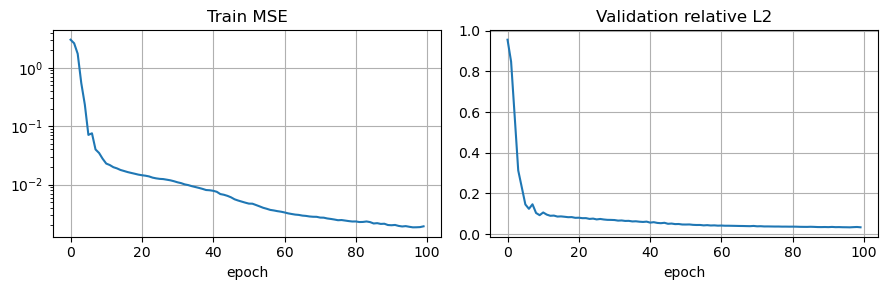

Test relative L2: mean=0.0354, median=0.0341, max=0.0613


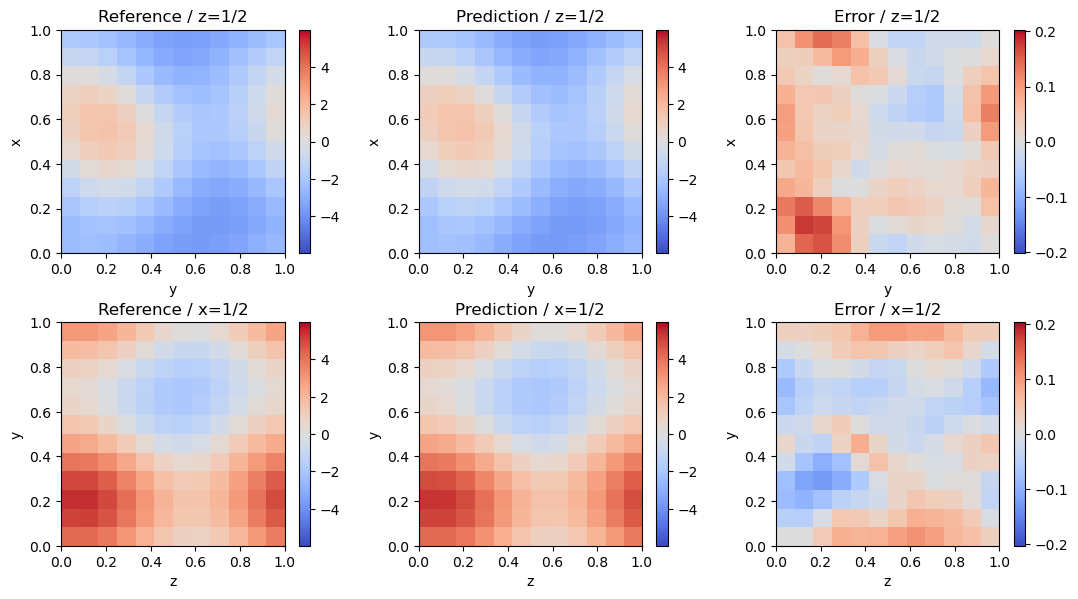

Reference discretized PDE residual: 5.408610687168352e-07
FNO discretized PDE residual: 0.1470152984093339


In [6]:
model = FNO3d(cin=2,width=8,modes=3)
history = fit(model,train_in,train_u,val_in,val_u,
              steps=epochs(100),batch=8,lr=0.003)
plot_history(history)
pred,error = report(model,test_in,test_u)
show_volume_slices(test_u,pred)

a = (test_in[:,0]+1).double()
f = (SCALE*test_in[:,1]).double()
def raw_relative_residual(u):
    r = apply_diffusion(u.double(),a)-f
    return r.flatten(1).norm(dim=1)/f.flatten(1).norm(dim=1)
print("Reference discretized PDE residual:",raw_relative_residual(test_u).mean().item())
print("FNO discretized PDE residual:",raw_relative_residual(pred).mean().item())

## 5. 网格加密时分开看两种误差

对前 4 条测试函数在双倍网格上重新采样 $a,f$，并重新求解离散 PDE。比较细网格参考解抽样到粗网格后的差异，估计网格误差；再比较 FNO 与细网格参考解，测量代理模型误差。这两者不可混为一个指标。

sigmoid 后的系数场仍光滑，但不再严格带限；粗网格和细网格解并不完全相同。

Test relative L2: mean=0.0411, median=0.0415, max=0.0491
fine reference PCG: {'iterations': 145, 'max_relative_residual': 8.836352396519658e-10}
reference coarse/fine difference: 0.016995321959257126
FNO fine-grid error: 0.04105263575911522


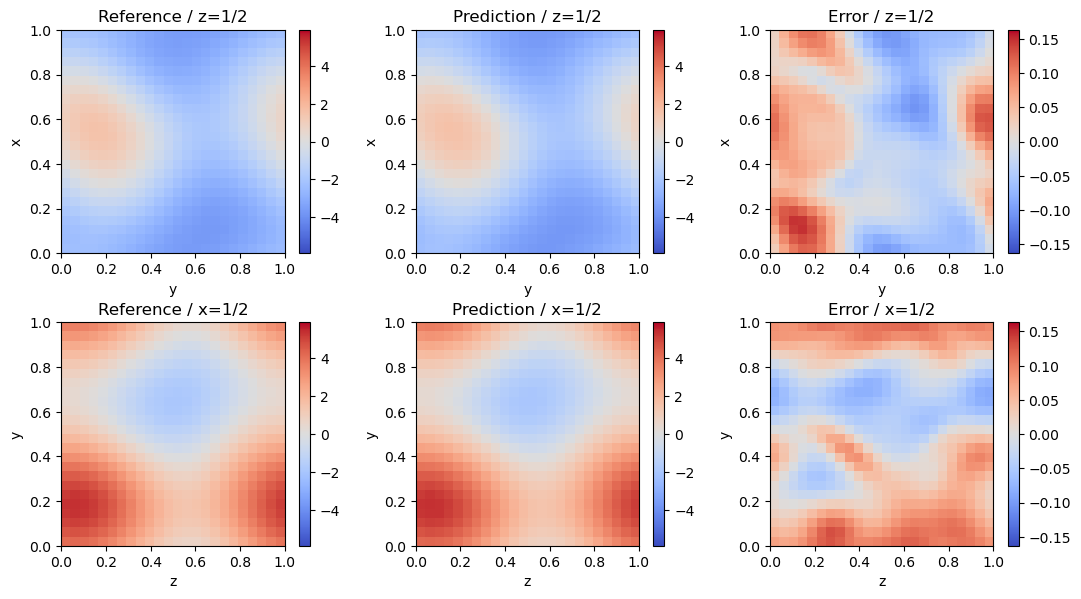

In [7]:
fine_in,fine_u,fine_info = diffusion_dataset(ac_test[:4],fc_test[:4],2*N)
finepred,fineerror = report(model,fine_in,fine_u)
reference_grid_change = relative_l2(fine_u[:,::2,::2,::2],test_u[:4]).mean()
print("fine reference PCG:",fine_info)
print("reference coarse/fine difference:",reference_grid_change.item())
print("FNO fine-grid error:",fineerror.mean().item())
show_volume_slices(fine_u,finepred)

**练习：** ① 将系数对比度逐渐增大并观察 PCG 迭代次数；② 比较调和平均与算术平均的离散系数；③ 为随机但固定 forcing 的版本训练单输入网络；④ 用本章离散残差为更多无标签 $(a,f)$ 添加 PINO 损失，并明确物理损失对应的是离散方程。

**自检：** 造 $f_h=A_hu_*$ 能验证求解器，但不能单独证明它正确逼近连续 PDE。